# Classifier comparison: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/classification/plot_classifier_comparison.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/classification/plot_classifier_comparison.html)).

**Scenario:** three synthetic 2-D datasets (moons, circles, linearly separable) are split 60/40, and each of ten
classifiers is wrapped in `make_pipeline(StandardScaler(), clf)`, fitted, scored on the test split and drawn
with its decision surface (`DecisionBoundaryDisplay`, using `decision_function` or `predict_proba`).

**Adaptations:**
- The Python reference runs the full example (all ten classifiers), with a smaller figure (dpi 60).
- Moxie runs the same pipelines for the classifiers that can follow `StandardScaler` in a typed Pipeline:
  **Nearest Neighbors, Linear SVM, RBF SVM and QDA**. It compares test scores (`pipe.score`), KNN predictions,
  SVM `decision_function` and QDA `predict_proba`, all forwarded through the Pipeline. Data are generated in
  Python and shared; labels are typed (`NDArray` for KNN, `List[Float64]` for SVC, `List[Int]` for QDA).
- Not reproduced in Moxie (`GAP` notes below): Decision Tree and Naive Bayes take non-`NDArray` inputs
  (`Features`, `List[List[Float64]]`), so `StandardScaler`'s output cannot feed them; Gaussian Process,
  Random Forest, Neural Net and AdaBoost were not exercised here (outside this family; several are scaffolds).
- The decision-surface figures are produced by the reference only. Moxie's comparisons are numerical on the
  test points.

**Determinism:** deterministic (fixed dataset seeds, `random_state=42`; KNN, SVC and QDA are deterministic).

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("pipeline/plot_classifier_comparison")

## 1. scikit-learn (Python reference)

The example code, with a smaller figure.

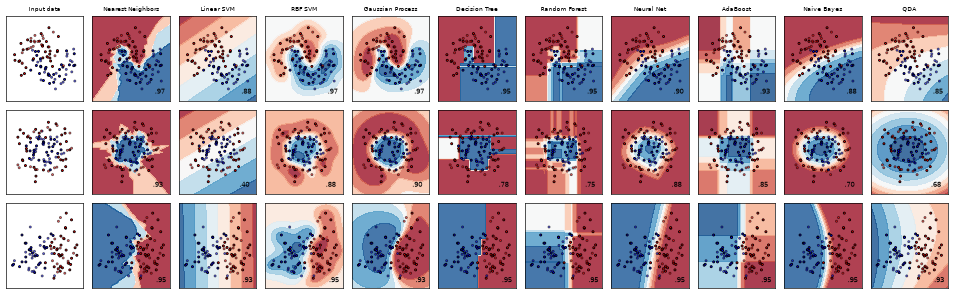

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap

from sklearn.datasets import make_circles, make_classification, make_moons
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

names = [
    "Nearest Neighbors",
    "Linear SVM",
    "RBF SVM",
    "Gaussian Process",
    "Decision Tree",
    "Random Forest",
    "Neural Net",
    "AdaBoost",
    "Naive Bayes",
    "QDA",
]

classifiers = [
    KNeighborsClassifier(3),
    SVC(kernel="linear", C=0.025, random_state=42),
    SVC(gamma=2, C=1, random_state=42),
    GaussianProcessClassifier(1.0 * RBF(1.0), random_state=42),
    DecisionTreeClassifier(max_depth=5, random_state=42),
    RandomForestClassifier(
        max_depth=5, n_estimators=10, max_features=1, random_state=42
    ),
    MLPClassifier(alpha=1, max_iter=1000, random_state=42),
    AdaBoostClassifier(random_state=42),
    GaussianNB(),
    QuadraticDiscriminantAnalysis(),
]

X, y = make_classification(
    n_features=2, n_redundant=0, n_informative=2, random_state=1, n_clusters_per_class=1
)
rng = np.random.RandomState(2)
X += 2 * rng.uniform(size=X.shape)
linearly_separable = (X, y)

datasets = [
    make_moons(noise=0.3, random_state=0),
    make_circles(noise=0.2, factor=0.5, random_state=1),
    linearly_separable,
]

figure = plt.figure(figsize=(16, 5), dpi=60)
i = 1
sk_scores = {}
splits = []
# iterate over datasets
for ds_cnt, ds in enumerate(datasets):
    # preprocess dataset, split into training and test part
    X, y = ds
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.4, random_state=42
    )
    splits.append((X_train, X_test, y_train, y_test))

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    # just plot the dataset first
    cm = plt.cm.RdBu
    cm_bright = ListedColormap(["#FF0000", "#0000FF"])
    ax = plt.subplot(len(datasets), len(classifiers) + 1, i)
    if ds_cnt == 0:
        ax.set_title("Input data", fontsize=7)
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cm_bright, edgecolors="k", s=6)
    ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=cm_bright, alpha=0.6, edgecolors="k", s=6)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(())
    ax.set_yticks(())
    i += 1

    # iterate over classifiers
    for name, clf in zip(names, classifiers):
        ax = plt.subplot(len(datasets), len(classifiers) + 1, i)

        clf = make_pipeline(StandardScaler(), clf)
        clf.fit(X_train, y_train)
        score = clf.score(X_test, y_test)
        sk_scores[(ds_cnt, name)] = score
        DecisionBoundaryDisplay.from_estimator(
            clf, X, cmap=cm, alpha=0.8, ax=ax, eps=0.5
        )
        ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cm_bright, edgecolors="k", s=6)
        ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=cm_bright, edgecolors="k", alpha=0.6, s=6)
        ax.set_xlim(x_min, x_max)
        ax.set_ylim(y_min, y_max)
        ax.set_xticks(())
        ax.set_yticks(())
        if ds_cnt == 0:
            ax.set_title(name, fontsize=7)
        ax.text(x_max - 0.3, y_min + 0.3, ("%.2f" % score).lstrip("0"), size=8, horizontalalignment="right")
        i += 1

plt.tight_layout()
plt.show()

In [3]:
# Reference values for the Moxie subset (same pipelines, refitted).
subset = ["Nearest Neighbors", "Linear SVM", "RBF SVM", "QDA"]
sk_subset_scores, sk_ref = [], {}
for d, (X_train, X_test, y_train, y_test) in enumerate(splits):
    nb.share(**{f"X_train{d}": X_train, f"X_test{d}": X_test, f"y_train{d}": y_train, f"y_test{d}": y_test})
    for name in subset:
        sk_subset_scores.append(sk_scores[(d, name)])
    sk_ref[f"knn_pred{d}"] = make_pipeline(StandardScaler(), KNeighborsClassifier(3)).fit(X_train, y_train).predict(X_test)
    sk_ref[f"linear_decision{d}"] = make_pipeline(StandardScaler(), SVC(kernel="linear", C=0.025, random_state=42)).fit(X_train, y_train).decision_function(X_test)
    sk_ref[f"rbf_decision{d}"] = make_pipeline(StandardScaler(), SVC(gamma=2, C=1, random_state=42)).fit(X_train, y_train).decision_function(X_test)
    sk_ref[f"qda_proba{d}"] = make_pipeline(StandardScaler(), QuadraticDiscriminantAnalysis()).fit(X_train, y_train).predict_proba(X_test)
print("sklearn step names:", [n for n, _ in make_pipeline(StandardScaler(), KNeighborsClassifier(3)).steps],
      [make_pipeline(StandardScaler(), c).steps[1][0] for c in (SVC(), QuadraticDiscriminantAnalysis())])

sklearn step names: ['standardscaler', 'kneighborsclassifier'] ['svc', 'quadraticdiscriminantanalysis']


## 2. Moxie (native Mojo)

`make_pipeline(StandardScaler(), clf)` for the four supported classifiers; `score`, `predict`, `decision_function` and `predict_proba` all go through the Pipeline.

In [4]:
%%mojo classifier_comparison
from numojo import NDArray
from moxie.pipeline import make_pipeline
from moxie.preprocessing import StandardScaler
from moxie.neighbors import KNeighborsClassifier
from moxie.svm import SVC
from moxie.discriminant_analysis import QuadraticDiscriminantAnalysis
from moxie_nb_io import load, load_ints, save, save_floats, save_ints


def floats(y: List[Int]) -> List[Float64]:
    var out = List[Float64]()
    for v in y:
        out.append(Float64(v))
    return out^


def array(y: List[Int]) raises -> NDArray[DType.float64]:
    var out = NDArray[DType.float64](nm_shape(len(y)))
    for i in range(len(y)):
        out.itemset(i, Float64(y[i]))
    return out^


from numojo import Shape
def nm_shape(n: Int) raises -> Shape:
    return Shape(n)


def main() raises:
    var scores = List[Float64]()
    for d in range(3):
        var X_train = load("X_train" + String(d))
        var X_test = load("X_test" + String(d))
        var y_train = load_ints("y_train" + String(d))
        var y_test = load_ints("y_test" + String(d))
        var tag = String(d)

        var knn = make_pipeline(StandardScaler(), KNeighborsClassifier(3))
        _ = knn.fit(X_train, array(y_train))
        scores.append(knn.score(X_test, array(y_test)))
        save("knn_pred" + tag, knn.predict(X_test))

        var linear = make_pipeline(StandardScaler(), SVC(kernel="linear", C=0.025, random_state=42))
        _ = linear.fit(X_train, floats(y_train))
        scores.append(linear.score(X_test, floats(y_test)))
        save("linear_decision" + tag, linear.decision_function(X_test))

        var rbf = make_pipeline(StandardScaler(), SVC(gamma=2.0, C=1, random_state=42))
        _ = rbf.fit(X_train, floats(y_train))
        scores.append(rbf.score(X_test, floats(y_test)))
        save("rbf_decision" + tag, rbf.decision_function(X_test))



        var qda = make_pipeline(StandardScaler(), QuadraticDiscriminantAnalysis())
        _ = qda.fit(X_train, y_train)
        scores.append(qda.score(X_test, y_test))
        save("qda_proba" + tag, qda.predict_proba(X_test))
        if d == 0:
            print("step names:", knn.transformer_name, knn.estimator_name, linear.estimator_name, qda.estimator_name)
    save_floats("scores", scores)


step names: standardscaler kneighborsclassifier svc quadraticdiscriminantanalysis


## 3. Side by side and parity

In [5]:
mx = nb.results["classifier_comparison"]
rows = [f"{d}:{name}" for d in range(3) for name in subset]
moxie_nb.side_by_side(sklearn=dict(zip(rows, np.round(sk_subset_scores, 3))),
                      moxie=dict(zip(rows, np.round(mx["scores"], 3))))
nb.compare("test accuracy (pipe.score), 3 datasets x 4 classifiers", np.array(sk_subset_scores), mx["scores"], exact=True)
for d in range(3):
    nb.compare(f"dataset {d}: KNN predict", sk_ref[f"knn_pred{d}"].astype(float), mx[f"knn_pred{d}"], exact=True)
    nb.compare(f"dataset {d}: linear SVM decision_function", sk_ref[f"linear_decision{d}"], mx[f"linear_decision{d}"],
               rtol=1e-6, atol=1e-6, reason="same SMO algorithm, stopping tol=1e-3; residual differences are rounding")
    nb.compare(f"dataset {d}: RBF SVM decision_function", sk_ref[f"rbf_decision{d}"], mx[f"rbf_decision{d}"],
               rtol=1e-6, atol=1e-6, reason="same SMO algorithm, stopping tol=1e-3; residual differences are rounding")
    nb.compare(f"dataset {d}: QDA predict_proba", sk_ref[f"qda_proba{d}"], mx[f"qda_proba{d}"],
               rtol=0, atol=1e-8, reason="discriminant_analysis family's documented Float64 parity bound "
               "(docs/discriminant_analysis/scope.md: 1e-8 relative to max magnitude, floor 1): per-class Jacobi "
               "SVD vs LAPACK plus summation order, amplified through exp of the log-likelihood")
nb.note("Decision Tree / Naive Bayes after StandardScaler", "GAP",
        "Moxie DecisionTreeClassifier takes `Features` and GaussianNB takes List[List[Float64]], not NDArray; the "
        "Pipeline rejects the intermediate type at compile time (owners: tree, naive_bayes).")
nb.note("Gaussian Process, Random Forest, Neural Net, AdaBoost", "GAP",
        "not exercised in this pipeline notebook; MLPClassifier and AdaBoostClassifier are API scaffolds in Moxie, "
        "GP/forest pipelines belong to their families' verification.")
nb.note("DecisionBoundaryDisplay", "GAP", "moxie.inspection display utilities are not used; Moxie values are compared on test points.")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
"test accuracy (pipe.score), 3 datasets x 4 classifiers",PASS,"(12,)","(12,)",,,exact,0 mismatches,
dataset 0: KNN predict,PASS,"(40,)","(40,)",,,exact,0 mismatches,
dataset 0: linear SVM decision_function,PASS,"(40,)","(40,)",0,0,"rtol=1e-06, atol=1e-06",,"same SMO algorithm, stopping tol=1e-3; residual differences are rounding"
dataset 0: RBF SVM decision_function,PASS,"(40,)","(40,)",0,0,"rtol=1e-06, atol=1e-06",,"same SMO algorithm, stopping tol=1e-3; residual differences are rounding"
dataset 0: QDA predict_proba,PASS,"(40, 2)","(40, 2)",2.81e-10,3.96e-10,"rtol=0, atol=1e-08",,"discriminant_analysis family's documented Float64 parity bound (docs/discriminant_analysis/scope.md: 1e-8 relative to max magnitude, floor 1): per-class Jacobi SVD vs LAPACK plus summation order, amplified through exp of the log-likelihood"
dataset 1: KNN predict,PASS,"(40,)","(40,)",,,exact,0 mismatches,
dataset 1: linear SVM decision_function,PASS,"(40,)","(40,)",0,0,"rtol=1e-06, atol=1e-06",,"same SMO algorithm, stopping tol=1e-3; residual differences are rounding"
dataset 1: RBF SVM decision_function,PASS,"(40,)","(40,)",0,0,"rtol=1e-06, atol=1e-06",,"same SMO algorithm, stopping tol=1e-3; residual differences are rounding"
dataset 1: QDA predict_proba,PASS,"(40, 2)","(40, 2)",6.57e-10,1.12e-09,"rtol=0, atol=1e-08",,"discriminant_analysis family's documented Float64 parity bound (docs/discriminant_analysis/scope.md: 1e-8 relative to max magnitude, floor 1): per-class Jacobi SVD vs LAPACK plus summation order, amplified through exp of the log-likelihood"
dataset 2: KNN predict,PASS,"(40,)","(40,)",,,exact,0 mismatches,
